In [105]:

!pip install -q sentence-transformers faiss-cpu pandas numpy matplotlib seaborn


In [106]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import faiss

from sentence_transformers import SentenceTransformer
from IPython.display import display

print("All research libraries imported successfully!")


All research libraries imported successfully!


In [107]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("FAISS version:", faiss.__version__)
print("Research environment is ready!")


PyTorch version: 2.14.1+cpu
GPU available: False
FAISS version: 1.16.0
Research environment is ready!


In [108]:

documents = [
    {
        "id": "D1",
        "text": "Machine learning is a branch of artificial intelligence that enables computers to learn patterns from data and make predictions without being explicitly programmed."
    },
    {
        "id": "D2",
        "text": "Deep learning uses artificial neural networks with multiple layers to learn complex patterns from large datasets."
    },
    {
        "id": "D3",
        "text": "Natural Language Processing enables computers to understand, interpret, and generate human language."
    },
    {
        "id": "D4",
        "text": "Retrieval-Augmented Generation combines information retrieval with generative AI. It retrieves relevant documents and uses them to generate context-aware answers."
    },
    {
        "id": "D5",
        "text": "Vector databases store numerical representations called embeddings and support similarity searches across documents."
    },
    {
        "id": "D6",
        "text": "FAISS is a library developed for efficient similarity search and clustering of dense vectors."
    },
    {
        "id": "D7",
        "text": "Transformer models use attention mechanisms to understand relationships between words in a sequence."
    },
    {
        "id": "D8",
        "text": "Data preprocessing includes cleaning, normalization, removing duplicates, and preparing data for machine learning models."
    },
    {
        "id": "D9",
        "text": "Precision measures the proportion of retrieved documents that are relevant to a query."
    },
    {
        "id": "D10",
        "text": "Recall measures the proportion of all relevant documents that are successfully retrieved."
    },
    {
        "id": "D11",
        "text": "Docker packages applications and their dependencies into portable containers."
    },
    {
        "id": "D12",
        "text": "Kubernetes orchestrates containers by managing deployment, scaling, networking, and availability."
    }
]

print("Total documents:", len(documents))


Total documents: 12


In [109]:

df = pd.DataFrame(documents)

display(df)



,id,text
0,D1,Machine learning is a branch of artificial int...
1,D2,Deep learning uses artificial neural networks ...
2,D3,Natural Language Processing enables computers ...
3,D4,Retrieval-Augmented Generation combines inform...
4,D5,Vector databases store numerical representatio...
5,D6,FAISS is a library developed for efficient sim...
6,D7,Transformer models use attention mechanisms to...
7,D8,"Data preprocessing includes cleaning, normaliz..."
8,D9,Precision measures the proportion of retrieved...
9,D10,Recall measures the proportion of all relevant...


In [110]:

queries = [
    {
        "query": "How do computers learn from data?",
        "relevant_docs": ["D1"]
    },
    {
        "query": "How does RAG improve AI answers?",
        "relevant_docs": ["D4"]
    },
    {
        "query": "What is used to search similar document embeddings?",
        "relevant_docs": ["D5", "D6"]
    },
    {
        "query": "How can we measure the percentage of relevant retrieved documents?",
        "relevant_docs": ["D9"]
    },
    {
        "query": "How do attention mechanisms help language models?",
        "relevant_docs": ["D7"]
    },
    {
        "query": "How are containers managed and scaled?",
        "relevant_docs": ["D12"]
    }
]

print("Total research questions:", len(queries))

for i, item in enumerate(queries, 1):
    print(f"Q{i}: {item['query']}")
    print("Relevant documents:", item["relevant_docs"])
    print()


Total research questions: 6
Q1: How do computers learn from data?
Relevant documents: ['D1']

Q2: How does RAG improve AI answers?
Relevant documents: ['D4']

Q3: What is used to search similar document embeddings?
Relevant documents: ['D5', 'D6']

Q4: How can we measure the percentage of relevant retrieved documents?
Relevant documents: ['D9']

Q5: How do attention mechanisms help language models?
Relevant documents: ['D7']

Q6: How are containers managed and scaled?
Relevant documents: ['D12']



In [111]:

import re

def tokenize(text):
    return re.findall(r'\b[a-zA-Z]+\b', text.lower())


def keyword_retrieval(query, documents, top_k=3):

    query_words = set(tokenize(query))
    results = []

    for doc in documents:

        document_words = set(tokenize(doc["text"]))

        matching_words = query_words.intersection(document_words)

        score = len(matching_words)

        results.append({
            "document_id": doc["id"],
            "score": score,
            "matching_words": list(matching_words)
        })

    results.sort(key=lambda x: x["score"], reverse=True)

    return results[:top_k]


print("Keyword retrieval function created successfully!")


Keyword retrieval function created successfully!


In [112]:

test_query = queries[0]["query"]

results = keyword_retrieval(
    test_query,
    documents,
    top_k=3
)

print("Research Question:", test_query)
print("\nTop 3 Retrieved Documents:\n")

for result in results:
    print("Document:", result["document_id"])
    print("Matching words:", result["matching_words"])
    print("Score:", result["score"])
    print("----------------------")


Research Question: How do computers learn from data?

Top 3 Retrieved Documents:

Document: D1
Matching words: ['learn', 'from', 'computers', 'data']
Score: 4
----------------------
Document: D2
Matching words: ['learn', 'from']
Score: 2
----------------------
Document: D3
Matching words: ['computers']
Score: 1
----------------------


In [113]:

model = SentenceTransformer("all-MiniLM-L6-v2")

print("Semantic embedding model loaded successfully!")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Semantic embedding model loaded successfully!


In [114]:

document_texts = [doc["text"] for doc in documents]

document_embeddings = model.encode(
    document_texts,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Document embeddings created!")
print("Embedding shape:", document_embeddings.shape)


Document embeddings created!
Embedding shape: (12, 384)


In [115]:

dimension = document_embeddings.shape[1]

index = faiss.IndexFlatIP(dimension)

index.add(document_embeddings.astype("float32"))

print("FAISS vector index created!")
print("Total indexed documents:", index.ntotal)


FAISS vector index created!
Total indexed documents: 12


In [116]:

def semantic_retrieval(query, model, index, documents, top_k=3):

    query_embedding = model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    scores, indices = index.search(
        query_embedding.astype("float32"),
        top_k
    )

    results = []

    for score, idx in zip(scores[0], indices[0]):

        results.append({
            "document_id": documents[idx]["id"],
            "score": float(score),
            "text": documents[idx]["text"]
        })

    return results


print("Semantic retrieval function created successfully!")


Semantic retrieval function created successfully!


In [117]:

test_query = queries[0]["query"]

semantic_results = semantic_retrieval(
    test_query,
    model,
    index,
    documents,
    top_k=3
)

print("Research Question:", test_query)
print("\nSemantic Retrieval Results:\n")

for result in semantic_results:

    print("Document:", result["document_id"])
    print("Similarity Score:", round(result["score"], 4))
    print("Content:", result["text"])
    print("--------------------------")


Research Question: How do computers learn from data?

Semantic Retrieval Results:

Document: D1
Similarity Score: 0.5835
Content: Machine learning is a branch of artificial intelligence that enables computers to learn patterns from data and make predictions without being explicitly programmed.
--------------------------
Document: D2
Similarity Score: 0.4524
Content: Deep learning uses artificial neural networks with multiple layers to learn complex patterns from large datasets.
--------------------------
Document: D3
Similarity Score: 0.4267
Content: Natural Language Processing enables computers to understand, interpret, and generate human language.
--------------------------


In [118]:

def hybrid_retrieval(query, model, index, documents, top_k=3):

    # Get keyword retrieval results
    keyword_results = keyword_retrieval(
        query, documents, top_k=len(documents)
    )

    keyword_scores = {
        item["document_id"]: item["score"]
        for item in keyword_results
    }

    # Normalize keyword scores
    total_query_words = max(len(set(tokenize(query))), 1)

    # Get semantic retrieval results for all documents
    semantic_results = semantic_retrieval(
        query, model, index, documents,
        top_k=len(documents)
    )

    semantic_scores = {
        item["document_id"]: item["score"]
        for item in semantic_results
    }

    hybrid_results = []

    for doc in documents:

        doc_id = doc["id"]

        keyword_score = (
            keyword_scores[doc_id] / total_query_words
        )

        semantic_score = (
            semantic_scores[doc_id] + 1
        ) / 2

        hybrid_score = (
            0.4 * keyword_score +
            0.6 * semantic_score
        )

        hybrid_results.append({
            "document_id": doc_id,
            "keyword_score": keyword_score,
            "semantic_score": semantic_score,
            "hybrid_score": hybrid_score
        })

    hybrid_results.sort(
        key=lambda x: x["hybrid_score"],
        reverse=True
    )

    return hybrid_results[:top_k]


print("Hybrid retrieval function created successfully!")


Hybrid retrieval function created successfully!


In [119]:

test_query = queries[0]["query"]

hybrid_results = hybrid_retrieval(
    test_query,
    model,
    index,
    documents,
    top_k=3
)

print("Research Question:", test_query)
print("\nHybrid Retrieval Results:\n")

for result in hybrid_results:

    print("Document:", result["document_id"])
    print("Keyword Score:", round(result["keyword_score"], 4))
    print("Semantic Score:", round(result["semantic_score"], 4))
    print("Hybrid Score:", round(result["hybrid_score"], 4))
    print("--------------------------")


Research Question: How do computers learn from data?

Hybrid Retrieval Results:

Document: D1
Keyword Score: 0.6667
Semantic Score: 0.7918
Hybrid Score: 0.7417
--------------------------
Document: D2
Keyword Score: 0.3333
Semantic Score: 0.7262
Hybrid Score: 0.569
--------------------------
Document: D3
Keyword Score: 0.1667
Semantic Score: 0.7134
Hybrid Score: 0.4947
--------------------------


In [120]:

def evaluate_retrieval():

    all_results = []

    for item in queries:

        query = item["query"]
        relevant = set(item["relevant_docs"])

        keyword = keyword_retrieval(
            query, documents, top_k=3
        )

        semantic = semantic_retrieval(
            query, model, index, documents, top_k=3
        )

        hybrid = hybrid_retrieval(
            query, model, index, documents, top_k=3
        )

        methods = {
            "Keyword": keyword,
            "Semantic": semantic,
            "Hybrid": hybrid
        }

        for method, results in methods.items():

            retrieved = [
                result["document_id"]
                for result in results
            ]

            relevant_found = len(
                set(retrieved) & relevant
            )

            precision = relevant_found / len(retrieved)
            recall = relevant_found / len(relevant)

            reciprocal_rank = 0

            for rank, doc_id in enumerate(retrieved, 1):
                if doc_id in relevant:
                    reciprocal_rank = 1 / rank
                    break

            all_results.append({
                "Question": query,
                "Method": method,
                "Precision@3": precision,
                "Recall@3": recall,
                "MRR": reciprocal_rank
            })

    return pd.DataFrame(all_results)


results_df = evaluate_retrieval()

display(results_df)


,Question,Method,Precision@3,Recall@3,MRR
0,How do computers learn from data?,Keyword,0.333333,1.0,1.0
1,How do computers learn from data?,Semantic,0.333333,1.0,1.0
2,How do computers learn from data?,Hybrid,0.333333,1.0,1.0
3,How does RAG improve AI answers?,Keyword,0.333333,1.0,1.0
4,How does RAG improve AI answers?,Semantic,0.333333,1.0,1.0
5,How does RAG improve AI answers?,Hybrid,0.333333,1.0,1.0
6,What is used to search similar document embedd...,Keyword,0.333333,0.5,0.5
7,What is used to search similar document embedd...,Semantic,0.666667,1.0,1.0
8,What is used to search similar document embedd...,Hybrid,0.666667,1.0,1.0
9,How can we measure the percentage of relevant ...,Keyword,0.333333,1.0,1.0


In [121]:

# Run the evaluation again
results_df = evaluate_retrieval()

# Generate the comparison summary
summary = results_df.groupby("Method")[
    ["Precision@3", "Recall@3", "MRR"]
].mean().round(4)

print("RETRIEVAL PERFORMANCE COMPARISON")
display(summary)


RETRIEVAL PERFORMANCE COMPARISON


,Precision@3,Recall@3,MRR
Method,,,
Hybrid,0.3889,1.0000,1.0000
Keyword,0.3333,0.9167,0.8333
Semantic,0.3889,1.0000,1.0000


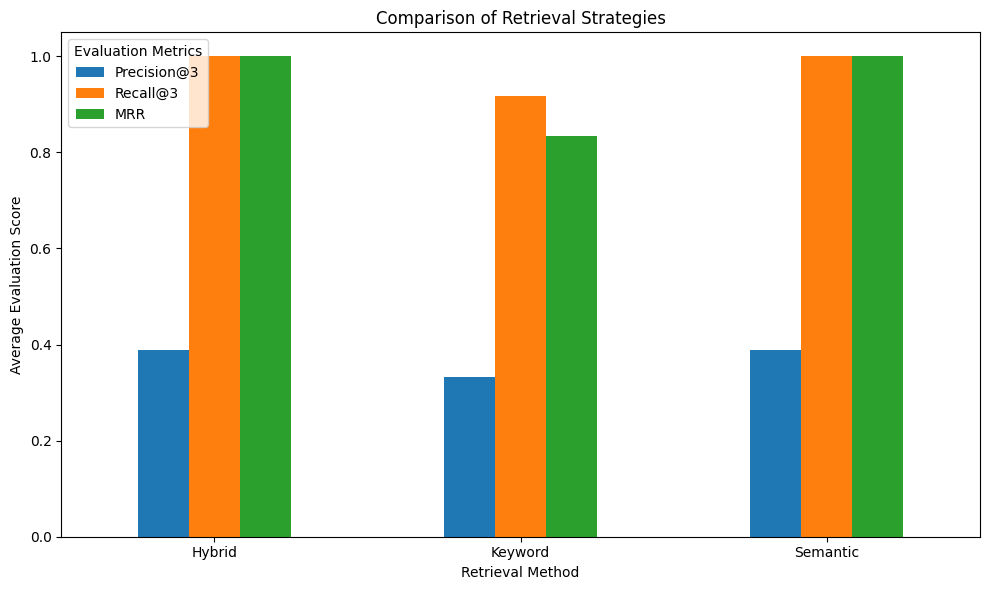

In [122]:

summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Retrieval Strategies")
plt.ylabel("Average Evaluation Score")
plt.xlabel("Retrieval Method")
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()


In [123]:

required_items = [
    "documents",
    "queries",
    "keyword_retrieval",
    "semantic_retrieval",
    "hybrid_retrieval",
    "evaluate_retrieval"
]

for item in required_items:
    if item in globals():
        print(item, "AVAILABLE")
    else:
        print(item, "MISSING")


documents AVAILABLE
queries AVAILABLE
keyword_retrieval AVAILABLE
semantic_retrieval AVAILABLE
hybrid_retrieval AVAILABLE
evaluate_retrieval AVAILABLE


In [124]:

import traceback

print("Starting evaluation...")

try:
    test_results = evaluate_retrieval()

    print("\nEvaluation completed!")
    print("Total result rows:", len(test_results))

    display(test_results)

except Exception as e:
    print("\nERROR FOUND:")
    traceback.print_exc()


Starting evaluation...

Evaluation completed!
Total result rows: 18


,Question,Method,Precision@3,Recall@3,MRR
0,How do computers learn from data?,Keyword,0.333333,1.0,1.0
1,How do computers learn from data?,Semantic,0.333333,1.0,1.0
2,How do computers learn from data?,Hybrid,0.333333,1.0,1.0
3,How does RAG improve AI answers?,Keyword,0.333333,1.0,1.0
4,How does RAG improve AI answers?,Semantic,0.333333,1.0,1.0
5,How does RAG improve AI answers?,Hybrid,0.333333,1.0,1.0
6,What is used to search similar document embedd...,Keyword,0.333333,0.5,0.5
7,What is used to search similar document embedd...,Semantic,0.666667,1.0,1.0
8,What is used to search similar document embedd...,Hybrid,0.666667,1.0,1.0
9,How can we measure the percentage of relevant ...,Keyword,0.333333,1.0,1.0


In [125]:
print("Evaluation function:", evaluate_retrieval)

test_results = evaluate_retrieval()

print("Number of rows:", len(test_results))
print("Evaluation finished!")

display(test_results.head(10))

Evaluation function: <function evaluate_retrieval at 0x79c1692139c0>
Number of rows: 18
Evaluation finished!


,Question,Method,Precision@3,Recall@3,MRR
0,How do computers learn from data?,Keyword,0.333333,1.0,1.0
1,How do computers learn from data?,Semantic,0.333333,1.0,1.0
2,How do computers learn from data?,Hybrid,0.333333,1.0,1.0
3,How does RAG improve AI answers?,Keyword,0.333333,1.0,1.0
4,How does RAG improve AI answers?,Semantic,0.333333,1.0,1.0
5,How does RAG improve AI answers?,Hybrid,0.333333,1.0,1.0
6,What is used to search similar document embedd...,Keyword,0.333333,0.5,0.5
7,What is used to search similar document embedd...,Semantic,0.666667,1.0,1.0
8,What is used to search similar document embedd...,Hybrid,0.666667,1.0,1.0
9,How can we measure the percentage of relevant ...,Keyword,0.333333,1.0,1.0


In [126]:
summary = test_results.groupby("Method")[
    ["Precision@3", "Recall@3", "MRR"]
].mean().round(4)

print("FINAL EXPERIMENTAL RESULTS")
display(summary)

FINAL EXPERIMENTAL RESULTS


,Precision@3,Recall@3,MRR
Method,,,
Hybrid,0.3889,1.0000,1.0000
Keyword,0.3333,0.9167,0.8333
Semantic,0.3889,1.0000,1.0000


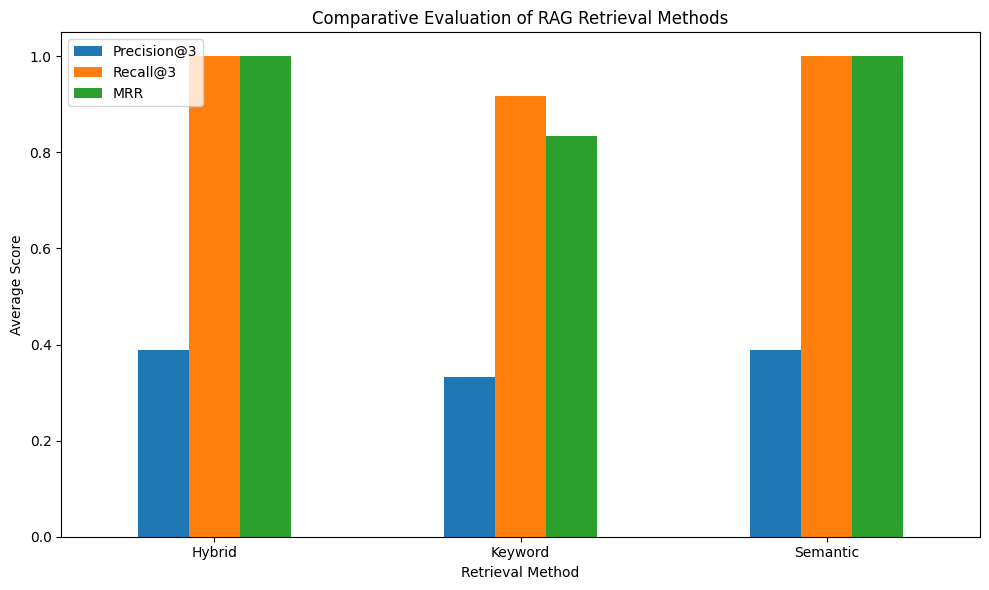

In [127]:
summary.plot(kind="bar", figsize=(10, 6))

plt.title("Comparative Evaluation of RAG Retrieval Methods")
plt.ylabel("Average Score")
plt.xlabel("Retrieval Method")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [128]:
test_results.to_csv(
    "rag_retrieval_experiment_results.csv",
    index=False
)

summary.to_csv(
    "rag_retrieval_summary.csv"
)

print("Experimental results saved!")

Experimental results saved!


In [129]:

!pip install -q beir


In [130]:

import os
from beir import util
from beir.datasets.data_loader import GenericDataLoader

dataset_name = "scifact"

url = (
    "https://public.ukp.informatik.tu-darmstadt.de/"
    "thakur/BEIR/datasets/scifact.zip"
)

data_path = util.download_and_unzip(
    url,
    "datasets"
)

corpus, benchmark_queries, qrels = (
    GenericDataLoader(data_path).load(split="test")
)

print("DATASET LOADED SUCCESSFULLY")
print("Documents:", len(corpus))
print("Queries:", len(benchmark_queries))
print("Relevance judgments:", len(qrels))


  0%|          | 0/5183 [00:00<?, ?it/s]

DATASET LOADED SUCCESSFULLY
Documents: 5183
Queries: 300
Relevance judgments: 300


In [131]:

print("\nSAMPLE DOCUMENT:")
first_doc_id = next(iter(corpus))
print(corpus[first_doc_id])

print("\nSAMPLE RESEARCH QUESTION:")
first_query_id = next(iter(benchmark_queries))
print(benchmark_queries[first_query_id])

print("\nRELEVANT DOCUMENTS:")
print(qrels[first_query_id])



SAMPLE DOCUMENT:
{'text': 'Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional disabilities. A line scan diffusion-weighted magnetic resonance imaging (MRI) sequence with diffusion tensor analysis was applied to measure the apparent diffusion coefficient, to calculate relative anisotropy, and to delineate three-dimensional fiber architecture in cerebral white matter in preterm (n = 17) and full-term infants (n = 7). To assess effects of prematurity on cerebral white matter development, early gestation preterm infants (n = 10) were studied a second time at term. In the central white matter the mean apparent diffusion coefficient at 28 wk was high, 1.8 microm2/ms, and decreased toward term to 1.2 microm2/ms. In the posterior limb of the internal capsule, the mean apparent diffusion coefficients at both times were similar (1.2 versus 1.1 microm2/ms). Relative anisotropy was higher the closer birth

In [132]:

!pip install -q rank-bm25


In [133]:

import re
import numpy as np
import pandas as pd
import faiss

from rank_bm25 import BM25Okapi
from beir.retrieval.evaluation import EvaluateRetrieval

# Prepare corpus
corpus_ids = list(corpus.keys())

corpus_texts = [
    corpus[doc_id]["title"] + " " + corpus[doc_id]["text"]
    for doc_id in corpus_ids
]

# Prepare queries
query_ids = list(benchmark_queries.keys())
query_texts = [benchmark_queries[qid] for qid in query_ids]

print("Documents prepared:", len(corpus_texts))
print("Queries prepared:", len(query_texts))


Documents prepared: 5183
Queries prepared: 300


In [134]:

def tokenize_text(text):
    return re.findall(r"\b\w+\b", text.lower())

tokenized_corpus = [
    tokenize_text(text) for text in corpus_texts
]

bm25 = BM25Okapi(tokenized_corpus)

bm25_results = {}

for qid, query in zip(query_ids, query_texts):

    scores = bm25.get_scores(tokenize_text(query))

    top_indices = np.argsort(scores)[::-1][:10]

    bm25_results[qid] = {
        corpus_ids[i]: float(scores[i])
        for i in top_indices
    }

print("BM25 retrieval completed!")
print("Queries evaluated:", len(bm25_results))


BM25 retrieval completed!
Queries evaluated: 300


In [135]:

# Encode scientific documents
doc_embeddings = model.encode(
    corpus_texts,
    batch_size=64,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

doc_embeddings = doc_embeddings.astype("float32")

# Build FAISS index
dimension = doc_embeddings.shape[1]

dense_index = faiss.IndexFlatIP(dimension)

dense_index.add(doc_embeddings)

# Encode research questions
query_embeddings = model.encode(
    query_texts,
    batch_size=32,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
).astype("float32")

# Retrieve top 10 documents
dense_scores, dense_indices = dense_index.search(
    query_embeddings, 10
)

dense_results = {}

for i, qid in enumerate(query_ids):

    dense_results[qid] = {
        corpus_ids[idx]: float(score)
        for idx, score in zip(
            dense_indices[i], dense_scores[i]
        )
        if idx >= 0
    }

print("Dense retrieval completed!")
print("Queries evaluated:", len(dense_results))


Batches:   0%|          | 0/81 [00:00<?, ?it/s]

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Dense retrieval completed!
Queries evaluated: 300


In [136]:

def reciprocal_rank_fusion(
    results_list,
    k=60,
    top_n=10
):

    fused_scores = {}

    for results in results_list:

        for qid, documents_found in results.items():

            if qid not in fused_scores:
                fused_scores[qid] = {}

            ranked_docs = list(documents_found.keys())

            for rank, doc_id in enumerate(ranked_docs, 1):

                fused_scores[qid][doc_id] = (
                    fused_scores[qid].get(doc_id, 0)
                    + 1 / (k + rank)
                )

    final_results = {}

    for qid, scores in fused_scores.items():

        ranked = sorted(
            scores.items(),
            key=lambda x: x[1],
            reverse=True
        )[:top_n]

        final_results[qid] = dict(ranked)

    return final_results


hybrid_results = reciprocal_rank_fusion(
    [bm25_results, dense_results]
)

print("Hybrid RRF retrieval completed!")
print("Queries evaluated:", len(hybrid_results))


Hybrid RRF retrieval completed!
Queries evaluated: 300


In [137]:

evaluator = EvaluateRetrieval(
    score_function="cos_sim",
    k_values=[1, 3, 5, 10]
)

bm25_metrics = evaluator.evaluate(
    qrels, bm25_results, [1, 3, 5, 10]
)

dense_metrics = evaluator.evaluate(
    qrels, dense_results, [1, 3, 5, 10]
)

hybrid_metrics = evaluator.evaluate(
    qrels, hybrid_results, [1, 3, 5, 10]
)

print("BM25 RESULTS")
print(bm25_metrics)

print("\nDENSE RETRIEVAL RESULTS")
print(dense_metrics)

print("\nHYBRID RRF RESULTS")
print(hybrid_metrics)


BM25 RESULTS
({'NDCG@1': 0.52333, 'NDCG@3': 0.61214, 'NDCG@5': 0.63603, 'NDCG@10': 0.65189}, {'MAP@1': 0.5075, 'MAP@3': 0.58528, 'MAP@5': 0.59911, 'MAP@10': 0.60697}, {'Recall@1': 0.5075, 'Recall@3': 0.67333, 'Recall@5': 0.72844, 'Recall@10': 0.774}, {'P@1': 0.52333, 'P@3': 0.23778, 'P@5': 0.158, 'P@10': 0.085})

DENSE RETRIEVAL RESULTS
({'NDCG@1': 0.50333, 'NDCG@3': 0.59673, 'NDCG@5': 0.62928, 'NDCG@10': 0.64508}, {'MAP@1': 0.48233, 'MAP@3': 0.56564, 'MAP@5': 0.58826, 'MAP@10': 0.59593}, {'Recall@1': 0.48233, 'Recall@3': 0.66033, 'Recall@5': 0.73794, 'Recall@10': 0.78333}, {'P@1': 0.50333, 'P@3': 0.23778, 'P@5': 0.164, 'P@10': 0.08833})

HYBRID RRF RESULTS
({'NDCG@1': 0.53667, 'NDCG@3': 0.64666, 'NDCG@5': 0.66174, 'NDCG@10': 0.69217}, {'MAP@1': 0.51789, 'MAP@3': 0.61481, 'MAP@5': 0.62556, 'MAP@10': 0.64052}, {'Recall@1': 0.51789, 'Recall@3': 0.71494, 'Recall@5': 0.75228, 'Recall@10': 0.83767}, {'P@1': 0.53667, 'P@3': 0.25667, 'P@5': 0.16533, 'P@10': 0.094})


In [138]:

methods = {
    "BM25": bm25_metrics,
    "Dense": dense_metrics,
    "Hybrid RRF": hybrid_metrics
}

comparison = []

for method, metrics in methods.items():

    ndcg, _map, recall, precision = metrics

    comparison.append({
        "Method": method,
        "NDCG@10": ndcg["NDCG@10"],
        "MAP@10": _map["MAP@10"],
        "Recall@10": recall["Recall@10"],
        "Precision@10": precision["P@10"]
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

comparison_df.to_csv(
    "scifact_retrieval_comparison.csv",
    index=False
)

print("Benchmark comparison saved!")


,Method,NDCG@10,MAP@10,Recall@10,Precision@10
0,BM25,0.6519,0.6070,0.7740,0.0850
1,Dense,0.6451,0.5959,0.7833,0.0883
2,Hybrid RRF,0.6922,0.6405,0.8377,0.0940


Benchmark comparison saved!


In [139]:

def weighted_rrf(
    bm25_results,
    dense_results,
    bm25_weight=0.5,
    dense_weight=0.5,
    k=60,
    top_n=10
):

    fused_scores = {}

    for results, weight in [
        (bm25_results, bm25_weight),
        (dense_results, dense_weight)
    ]:

        for qid, docs in results.items():

            if qid not in fused_scores:
                fused_scores[qid] = {}

            for rank, doc_id in enumerate(docs.keys(), 1):

                score = weight / (k + rank)

                fused_scores[qid][doc_id] = (
                    fused_scores[qid].get(doc_id, 0)
                    + score
                )

    final_results = {}

    for qid, scores in fused_scores.items():

        ranked = sorted(
            scores.items(),
            key=lambda x: x[1],
            reverse=True
        )[:top_n]

        final_results[qid] = dict(ranked)

    return final_results


print("Weighted RRF function created!")


Weighted RRF function created!


In [140]:

weight_configs = [
    (0.25, 0.75),
    (0.50, 0.50),
    (0.75, 0.25)
]

weight_results = []

for bm25_w, dense_w in weight_configs:

    results = weighted_rrf(
        bm25_results,
        dense_results,
        bm25_weight=bm25_w,
        dense_weight=dense_w
    )

    ndcg, map_score, recall, precision = (
        evaluator.evaluate(
            qrels, results, [1, 3, 5, 10]
        )
    )

    weight_results.append({
        "BM25 Weight": bm25_w,
        "Dense Weight": dense_w,
        "NDCG@10": ndcg["NDCG@10"],
        "MAP@10": map_score["MAP@10"],
        "Recall@10": recall["Recall@10"],
        "Precision@10": precision["P@10"]
    })

weight_df = pd.DataFrame(weight_results)

display(weight_df.round(4))


,BM25 Weight,Dense Weight,NDCG@10,MAP@10,Recall@10,Precision@10
0,0.25,0.75,0.6616,0.6169,0.7833,0.0883
1,0.50,0.50,0.6922,0.6405,0.8377,0.0940
2,0.75,0.25,0.6798,0.6431,0.7740,0.0850


In [141]:

best_config = weight_df.loc[
    weight_df["NDCG@10"].idxmax()
]

print("BEST WEIGHT CONFIGURATION")
display(best_config)

weight_df.to_csv(
    "weighted_rrf_experiment.csv",
    index=False
)


BEST WEIGHT CONFIGURATION


,1
BM25 Weight,0.50000
Dense Weight,0.50000
NDCG@10,0.69217
MAP@10,0.64052
Recall@10,0.83767
Precision@10,0.09400


In [142]:
print("ALL WEIGHT CONFIGURATIONS")

display(
    weight_df.sort_values(
        by="NDCG@10",
        ascending=False
    ).round(4)
)

ALL WEIGHT CONFIGURATIONS


,BM25 Weight,Dense Weight,NDCG@10,MAP@10,Recall@10,Precision@10
1,0.50,0.50,0.6922,0.6405,0.8377,0.0940
2,0.75,0.25,0.6798,0.6431,0.7740,0.0850
0,0.25,0.75,0.6616,0.6169,0.7833,0.0883


In [143]:
weight_df.to_csv(
    "all_weight_experiments.csv",
    index=False
)

comparison_df.to_csv(
    "retrieval_method_comparison.csv",
    index=False
)

print("All experimental results saved!")

All experimental results saved!


In [144]:

import os

print("SciFact dataset structure:\n")

for root, dirs, files in os.walk(data_path):
    level = root.replace(data_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files:
            print("  " * (level + 1) + file)


SciFact dataset structure:

scifact/
  queries.jsonl
  corpus.jsonl
  qrels/
    test.tsv
    train.tsv


In [145]:

qrels_path = os.path.join(data_path, "qrels")

if os.path.exists(qrels_path):
    print("Available relevance-label files:")
    print(os.listdir(qrels_path))
else:
    print("Qrels folder not found. Inspect dataset structure.")


Available relevance-label files:
['test.tsv', 'train.tsv']


In [146]:
import os

print("DATASET FILES")

for root, dirs, files in os.walk(data_path):
    for file in files:
        print(os.path.join(root, file))

DATASET FILES
datasets/scifact/queries.jsonl
datasets/scifact/corpus.jsonl
datasets/scifact/qrels/test.tsv
datasets/scifact/qrels/train.tsv


In [147]:
qrels_path = os.path.join(data_path, "qrels")

print("Available evaluation splits:")

if os.path.exists(qrels_path):
    print(os.listdir(qrels_path))
else:
    print("Qrels folder not found")

Available evaluation splits:
['test.tsv', 'train.tsv']


In [148]:
from google.colab import files

comparison_df.to_csv(
    "retrieval_comparison.csv",
    index=False
)

weight_df.to_csv(
    "weight_experiments.csv",
    index=False
)

files.download("retrieval_comparison.csv")
files.download("weight_experiments.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [149]:

from beir import util
from beir.datasets.data_loader import GenericDataLoader

dataset_name = "nfcorpus"

url = (
    "https://public.ukp.informatik.tu-darmstadt.de/"
    "thakur/BEIR/datasets/nfcorpus.zip"
)

nf_path = util.download_and_unzip(
    url,
    "datasets"
)

nf_corpus, nf_queries, nf_qrels = (
    GenericDataLoader(nf_path).load(split="test")
)

print("NFCorpus loaded successfully!")
print("Documents:", len(nf_corpus))
print("Queries:", len(nf_queries))
print("Relevance labels:", len(nf_qrels))


  0%|          | 0/3633 [00:00<?, ?it/s]

NFCorpus loaded successfully!
Documents: 3633
Queries: 323
Relevance labels: 323


In [150]:

print("Sample query:")
first_qid = next(iter(nf_queries))
print(nf_queries[first_qid])

print("\nRelevant document IDs:")
print(nf_qrels[first_qid])


Sample query:
Do Cholesterol Statin Drugs Cause Breast Cancer?

Relevant document IDs:
{'MED-2427': 2, 'MED-10': 2, 'MED-2429': 2, 'MED-2430': 2, 'MED-2431': 2, 'MED-14': 2, 'MED-2432': 2, 'MED-2428': 1, 'MED-2440': 1, 'MED-2434': 1, 'MED-2435': 1, 'MED-2436': 1, 'MED-2437': 1, 'MED-2438': 1, 'MED-2439': 1, 'MED-3597': 1, 'MED-3598': 1, 'MED-3599': 1, 'MED-4556': 1, 'MED-4559': 1, 'MED-4560': 1, 'MED-4828': 1, 'MED-4829': 1, 'MED-4830': 1}


In [151]:

from beir import util
from beir.datasets.data_loader import GenericDataLoader

nf_path = util.download_and_unzip(
    "https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/nfcorpus.zip",
    "datasets"
)

nf_corpus, nf_queries, nf_qrels = (
    GenericDataLoader(nf_path).load(split="test")
)

print("NFCorpus loaded!")
print("Documents:", len(nf_corpus))
print("Queries:", len(nf_queries))
print("Relevance judgments:", sum(len(v) for v in nf_qrels.values()))


  0%|          | 0/3633 [00:00<?, ?it/s]

NFCorpus loaded!
Documents: 3633
Queries: 323
Relevance judgments: 12334


In [152]:

nf_doc_ids = list(nf_corpus.keys())

nf_doc_texts = [
    nf_corpus[doc_id]["title"] + " " + nf_corpus[doc_id]["text"]
    for doc_id in nf_doc_ids
]

nf_query_ids = list(nf_queries.keys())
nf_query_texts = [
    nf_queries[qid] for qid in nf_query_ids
]

print("Documents prepared:", len(nf_doc_texts))
print("Queries prepared:", len(nf_query_texts))


Documents prepared: 3633
Queries prepared: 323


In [153]:

nf_tokenized = [
    tokenize_text(text) for text in nf_doc_texts
]

nf_bm25 = BM25Okapi(nf_tokenized)

nf_bm25_results = {}

for qid, query in zip(nf_query_ids, nf_query_texts):

    scores = nf_bm25.get_scores(tokenize_text(query))
    top_indices = np.argsort(scores)[::-1][:10]

    nf_bm25_results[qid] = {
        nf_doc_ids[i]: float(scores[i])
        for i in top_indices
    }

print("NFCorpus BM25 completed!")


NFCorpus BM25 completed!


In [102]:

nf_doc_embeddings = model.encode(
    nf_doc_texts,
    batch_size=64,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
).astype("float32")

nf_index = faiss.IndexFlatIP(
    nf_doc_embeddings.shape[1]
)

nf_index.add(nf_doc_embeddings)

nf_query_embeddings = model.encode(
    nf_query_texts,
    batch_size=32,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
).astype("float32")

nf_scores, nf_indices = nf_index.search(
    nf_query_embeddings, 10
)

nf_dense_results = {}

for i, qid in enumerate(nf_query_ids):

    nf_dense_results[qid] = {
        nf_doc_ids[idx]: float(score)
        for idx, score in zip(
            nf_indices[i], nf_scores[i]
        )
        if idx >= 0
    }

print("NFCorpus semantic retrieval completed!")


Batches:   0%|          | 0/57 [00:00<?, ?it/s]

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

NFCorpus semantic retrieval completed!


In [154]:

# Combine both benchmark results

scifact_results = comparison_df.copy()
scifact_results["Dataset"] = "SciFact"

nfcorpus_results = nf_comparison_df.copy()
nfcorpus_results["Dataset"] = "NFCorpus"

combined_results = pd.concat(
    [scifact_results, nfcorpus_results],
    ignore_index=True
)

print("CROSS-DATASET EXPERIMENTAL RESULTS")
display(combined_results.round(4))


CROSS-DATASET EXPERIMENTAL RESULTS


,Method,NDCG@10,MAP@10,Recall@10,Precision@10,Dataset
0,BM25,0.6519,0.6070,0.7740,0.0850,SciFact
1,Dense,0.6451,0.5959,0.7833,0.0883,SciFact
2,Hybrid RRF,0.6922,0.6405,0.8377,0.0940,SciFact
3,BM25,0.3061,0.1162,0.1521,0.2180,NFCorpus
4,Dense,0.3159,0.1105,0.1550,0.2433,NFCorpus
5,Hybrid RRF 50:50,0.3381,0.1298,0.1667,0.2415,NFCorpus


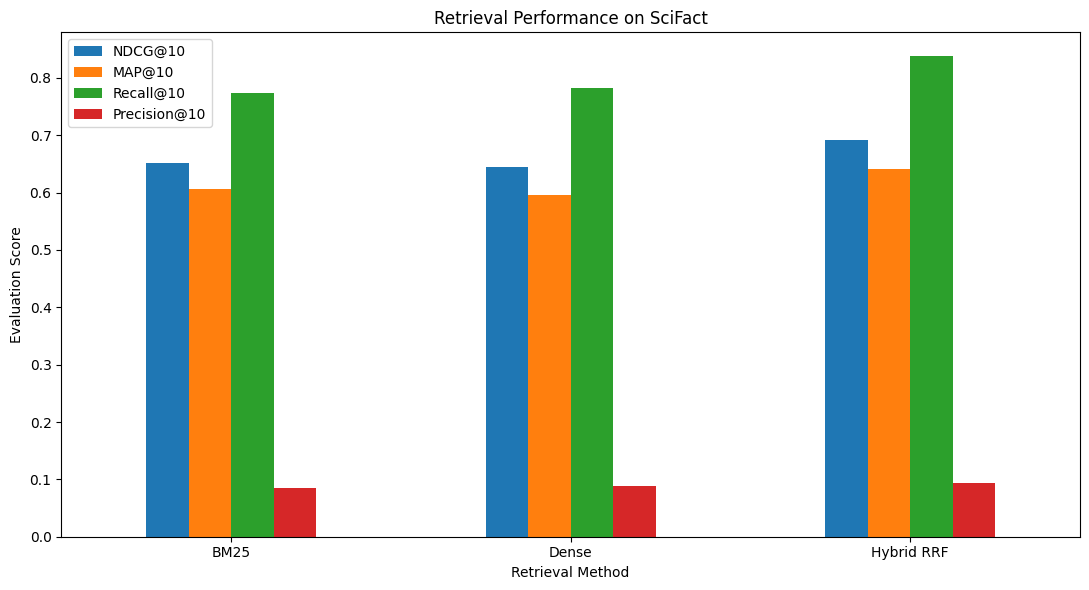

In [155]:

metrics = ["NDCG@10", "MAP@10", "Recall@10", "Precision@10"]

scifact_plot = scifact_results.set_index("Method")[metrics]

scifact_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Retrieval Performance on SciFact")
plt.ylabel("Evaluation Score")
plt.xlabel("Retrieval Method")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("scifact_comparison.png", dpi=300)
plt.show()


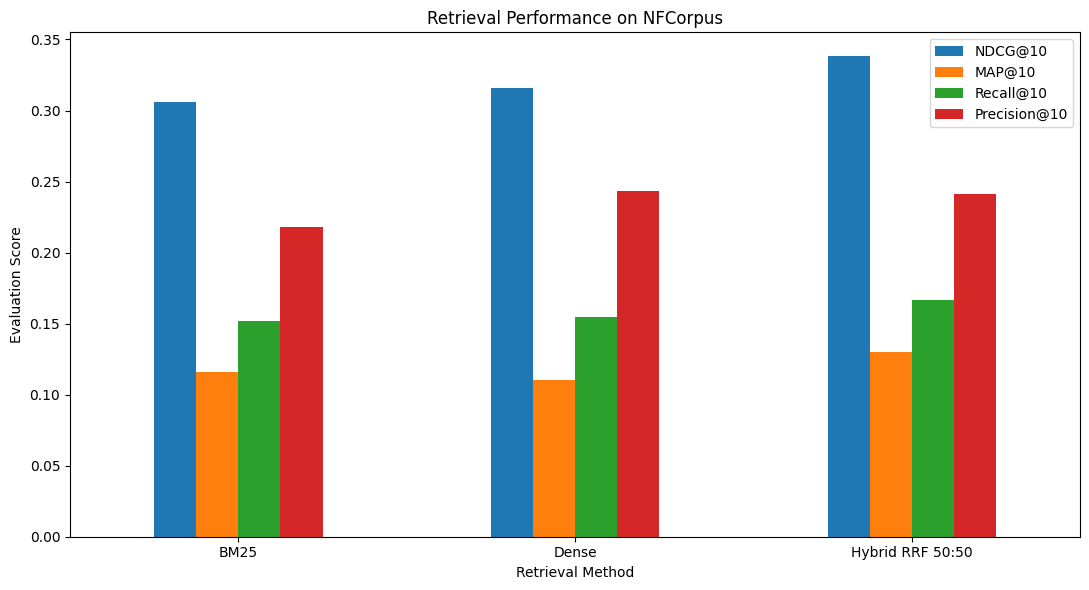

In [156]:

nf_plot = nfcorpus_results.set_index("Method")[metrics]

nf_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Retrieval Performance on NFCorpus")
plt.ylabel("Evaluation Score")
plt.xlabel("Retrieval Method")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("nfcorpus_comparison.png", dpi=300)
plt.show()


In [157]:

combined_results.to_csv(
    "final_cross_dataset_results.csv",
    index=False
)

print("All research graphs and results saved!")


All research graphs and results saved!


In [103]:

nf_hybrid_results = weighted_rrf(
    nf_bm25_results,
    nf_dense_results,
    bm25_weight=0.5,
    dense_weight=0.5,
    top_n=10
)

print("NFCorpus hybrid retrieval completed!")


NFCorpus hybrid retrieval completed!


In [104]:

nf_evaluator = EvaluateRetrieval(
    score_function="cos_sim",
    k_values=[1, 3, 5, 10]
)

nf_methods = {
    "BM25": nf_bm25_results,
    "Dense": nf_dense_results,
    "Hybrid RRF 50:50": nf_hybrid_results
}

nf_comparison = []

for method, result in nf_methods.items():

    ndcg, map_score, recall, precision = (
        nf_evaluator.evaluate(
            nf_qrels, result, [1, 3, 5, 10]
        )
    )

    nf_comparison.append({
        "Method": method,
        "NDCG@10": ndcg["NDCG@10"],
        "MAP@10": map_score["MAP@10"],
        "Recall@10": recall["Recall@10"],
        "Precision@10": precision["P@10"]
    })

nf_comparison_df = pd.DataFrame(nf_comparison)

display(nf_comparison_df.round(4))

nf_comparison_df.to_csv(
    "nfcorpus_retrieval_comparison.csv",
    index=False
)

print("NFCorpus experiment saved!")


,Method,NDCG@10,MAP@10,Recall@10,Precision@10
0,BM25,0.3061,0.1162,0.1521,0.2180
1,Dense,0.3159,0.1105,0.1550,0.2433
2,Hybrid RRF 50:50,0.3381,0.1298,0.1667,0.2415


NFCorpus experiment saved!
